In [ ]:
# simple parallel workflow --> multiple tasks running independently
# while having paralle workflow we have partial updates and not full state update,
# hence every function is returning only the partially calc values and not entire state 

In [ ]:
from langgraph.graph import StateGraph , START, END
from langchain_groq import ChatGroq
from typing import TypedDict
from dotenv import load_dotenv
import os
from langgraph.checkpoint.memory import MemorySaver

model = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,
    groq_api_key="your API key"
)
print(model)


metadata={'lc_versions': {'langchain-core': '1.6.7', 'langchain': '1.4.3'}} profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True} client=<groq.resources.chat.completions.Completions object at 0x000002151DE1E490> async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000002151DE1EE90> model_name='openai/gpt-oss-120b' temperature=1e-08 model_kwargs={} groq_api_key=SecretStr('**********')


In [ ]:
#  input variables and their datatypes

class CricketInputState(TypedDict):
# input data
    runs : int 
    balls: int 
    fours : int 
    sixes : int 

# calculate these 
    strike_rate : float
    balls_per_boun : float
    boundary_perc : float
    summary : str




In [33]:
def strike_rate_fn(state : CricketInputState):
    
    sr = (state['runs']/state['balls'])*100
    # state['strike_rate'] = sr

    return {'strike_rate': sr}

In [34]:
def balls_per_boun_fn(state : CricketInputState):

    bpb = state['balls']/(state['fours'] + state['sixes'])

    # state['balls_per_boun'] = bpb

    return {'balls_per_boun' : bpb}

In [42]:
def boundary_perc_fn(state : CricketInputState ):
    boun_perc = ((state['fours'] * 4) + (state['sixes'] * 6)/state['runs'])*100
    # boun_perc = (tot_boun_run/state['runs']) * 100

    # state['boun_perc'] = boun_perc
    
    return {'boundary_perc' : boun_perc}


In [43]:
def summary_fn(state : CricketInputState):

    summary = f"""
Strike rate - {state['strike_rate']} \n
Balls per boundary - {state['balls_per_boun']} \n
Boundary percent - {state['boundary_perc']}

"""
    return {'summary': summary}

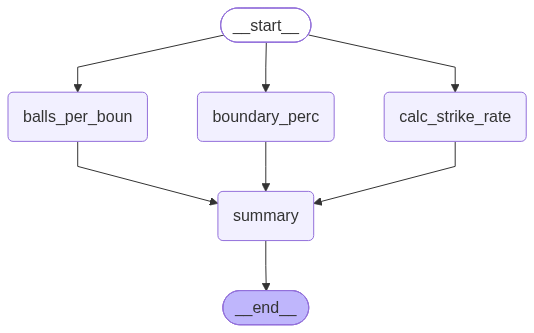

In [44]:
# graph
graph = StateGraph(CricketInputState)

# nodes 
graph.add_node('calc_strike_rate', strike_rate_fn)
graph.add_node('balls_per_boun', balls_per_boun_fn)
graph.add_node('boundary_perc', boundary_perc_fn)
graph.add_node('summary', summary_fn)





# edges
graph.add_edge(START, 'calc_strike_rate')
graph.add_edge(START, 'balls_per_boun')
graph.add_edge(START, 'boundary_perc')

graph.add_edge('calc_strike_rate', 'summary')
graph.add_edge('balls_per_boun', 'summary')
graph.add_edge('boundary_perc', 'summary')

graph.add_edge('summary', END)





#compile 
workflow = graph.compile()
workflow


In [45]:
Initialstate = {
    'runs' : 100,
    'balls' : 50,
    'fours' : 10,
    'sixes' : 5
}

workflow.invoke(Initialstate)

{'runs': 100,
 'balls': 50,
 'fours': 10,
 'sixes': 5,
 'strike_rate': 200.0,
 'balls_per_boun': 3.3333333333333335,
 'boundary_perc': 4029.9999999999995}